<a href="https://colab.research.google.com/github/CLukashanets-MC/DATA201-assignments/blob/main/week-09_decision-trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA201 assignment, week 09: decision trees

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

!pip -q install ISLP

from ISLP import load_data
carseats = load_data('Carseats')

carseats

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...
395,12.57,138,108,17,203,128,Good,33,14,Yes,Yes
396,6.14,139,23,3,37,120,Medium,55,11,No,Yes
397,7.41,162,26,12,368,159,Medium,40,18,Yes,Yes
398,5.94,100,79,7,284,95,Bad,50,12,Yes,Yes


In [10]:
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

print(carseats['HighSales'].value_counts())
# stratification required

HighSales
0    236
1    164
Name: count, dtype: int64


In [11]:
print(carseats.isna().sum())

X = pd.get_dummies(carseats.drop(columns='HighSales'), columns = ['ShelveLoc', 'Urban', 'US']).astype(int)
y = carseats.HighSales

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state=0, stratify=y
)

CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
HighSales      0
dtype: int64


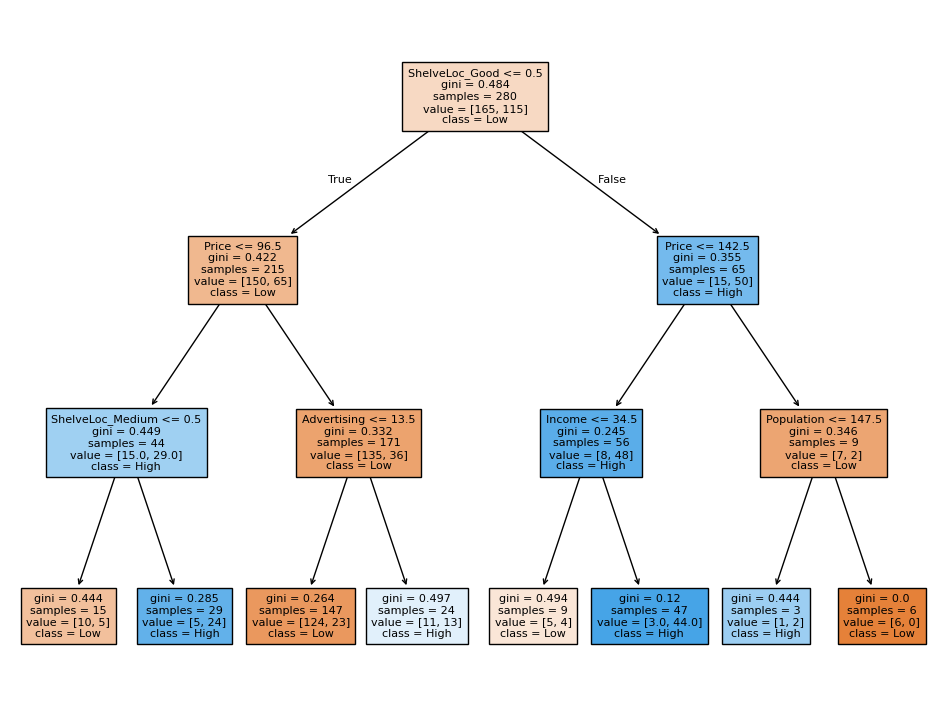

train accuracy: 0.8143
test accuracy: 0.6833


In [12]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)

plt.figure(figsize=(12,9))
plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['Low', 'High'],
          filled=True,
          fontsize=8
          )
plt.show()

print(f'train accuracy: {round(tree.score(X_train, y_train), 4)}')
print(f'test accuracy: {round(tree.score(X_test, y_test), 4)}')

Text(0, 0.5, 'trained mean accuracy')

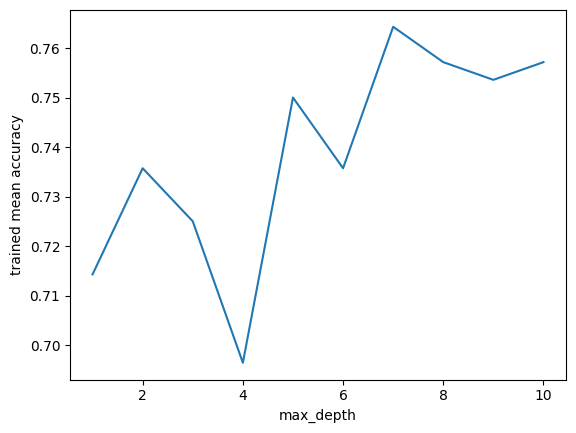

In [13]:
depths = range(1,11)
accuracies = []

for i in depths:
  t=DecisionTreeClassifier(max_depth=i)
  scores = cross_val_score(t, X_train, y_train, cv=5, scoring='accuracy')
  accuracies.append(scores.mean())

plt.plot(depths, accuracies)
plt.xlabel('max_depth')
plt.ylabel('trained mean accuracy')

In [15]:
ftree = DecisionTreeClassifier(max_depth=7, random_state=0).fit(X_train, y_train)
print(f'test accuracy: {round(ftree.score(X_test, y_test), 4)}')

test accuracy: 0.7167


Wrap-up questions:

1. What does a leaf predict in a classification tree? In a regression tree?

In a classification tree, each leaf predicts the target class based on the class of a given predictor variable. Regression trees work with numerical variables, so each leaf decides class based on a determined threshold.

2. Why did the full tree reach 100% training accuracy but do worse on the test set?

The decision tree overfit on the training data, making it worse at predicting new data.

3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?

Pre-pruning (before tree has grown, with `max_depth`, `max_leaf_nodes`) and post-pruning (simplifying a fully-grown tree, with `ccp_alpha`). For this assignment, cross-validation tuned `max_depth`.

4. Why do we not need to scale features before fitting a tree?

Decision trees process variables separately, using a determined threshold.

5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

An importance score of 0 only indicates that the model did not use the variable.

6. Name one strength and one weakness of a single decision tree that you saw in this lab.

Strength: trees are very easy to read and interpret.

Weakness: decision trees can very easily overfit on the training data.